# 01. Metadata Curation & Pilot Cohort Exploratory Data Analysis (EDA)
### Project: Tumor-Fraction-Aware AI for Early Multi-Cancer Detection from Liquid Biopsy

This starter notebook performs exploratory analysis of cfDNA sequencing manifests (`SraRunTable.csv` / `sample_sheet.csv`) across public cohorts:
- **PRJNA795275 (DELFI Multi-Cancer Cohort)**
- **GSE71378 (Snyder et al. Nucleosome & sWGS Cohort)**
- **EGAD00001006869 (European Genome-phenome Archive Validation Cohort)**

In [1]:
import os
import sys
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting aesthetic
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print(f"Python Version: {sys.version}")

Python Version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


## 1. Load Central Configuration

In [2]:
config_path = Path("../config/config.yaml")
with open(config_path, "r") as f:
    config = yaml.safe_load(f)

print("Project:", config["project"]["title"])
print("Target In Silico Dilution Fractions:", config["in_silico_dilution"]["fractions"])
print("Cross-Validation Strategy:", config["training"]["cv_strategy"])

Project: Tumor-Fraction-Aware AI for Early Multi-Cancer Detection from Liquid Biopsy
Target In Silico Dilution Fractions: [0.1, 0.05, 0.01, 0.001]
Cross-Validation Strategy: GroupKFold


## 2. Load Sample Manifest & Cohort Annotations

In [3]:
manifest_path = Path("../data/metadata/sample_sheet_template.csv")
if not manifest_path.exists():
    manifest_path = Path("../data/metadata/sample_sheet.csv")

df = pd.read_csv(manifest_path)
print(f"Total cohort records: {len(df)}")
display(df.head(10))

Total cohort records: 8


,sample_id,patient_id,cohort,condition,cancer_type,stage,measured_tf,bam_path
0,SRR12340001,PT_CTRL_001,PRJNA795275,Healthy,Healthy,NaN,0.000,data/raw/bam/SRR12340001.sorted.bam
1,SRR12340002,PT_CTRL_002,PRJNA795275,Healthy,Healthy,NaN,0.000,data/raw/bam/SRR12340002.sorted.bam
2,SRR12340003,PT_CTRL_003,PRJNA795275,Healthy,Healthy,NaN,0.000,data/raw/bam/SRR12340003.sorted.bam
3,SRR12340004,PT_LUNG_001,PRJNA795275,Cancer,Lung,Stage I,0.045,data/raw/bam/SRR12340004.sorted.bam
4,SRR12340005,PT_LUNG_002,PRJNA795275,Cancer,Lung,Stage II,0.112,data/raw/bam/SRR12340005.sorted.bam
5,SRR12340006,PT_CRC_001,PRJNA795275,Cancer,Colorectal,Stage I,0.038,data/raw/bam/SRR12340006.sorted.bam
6,SRR12340007,PT_CRC_002,PRJNA795275,Cancer,Colorectal,Stage III,0.185,data/raw/bam/SRR12340007.sorted.bam
7,SRR12340008,PT_BRCA_001,PRJNA795275,Cancer,Breast,Stage I,0.021,data/raw/bam/SRR12340008.sorted.bam


## 3. Distribution of Conditions, Cancer Types, and Clinical Stages

C:\Users\angel\AppData\Local\Temp\ipykernel_19556\1521874332.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="stage", order=sorted(df["stage"].dropna().unique()), ax=axes[1], palette="viridis")


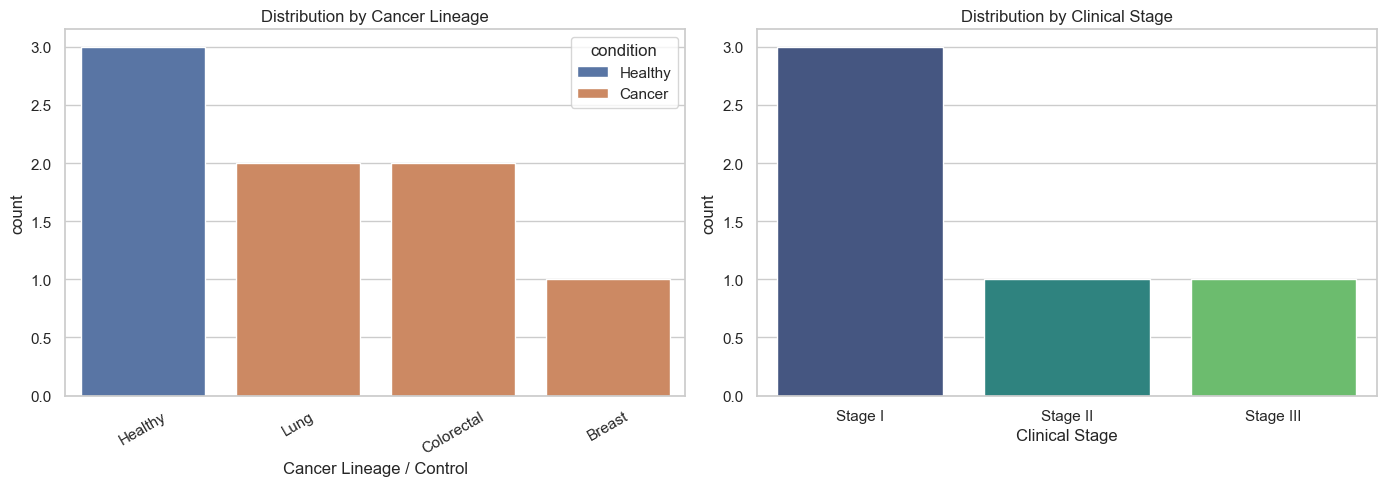

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="cancer_type", hue="condition", ax=axes[0])
axes[0].set_title("Distribution by Cancer Lineage")
axes[0].set_xlabel("Cancer Lineage / Control")
axes[0].tick_params(axis="x", rotation=30)

sns.countplot(data=df, x="stage", order=sorted(df["stage"].dropna().unique()), ax=axes[1], palette="viridis")
axes[1].set_title("Distribution by Clinical Stage")
axes[1].set_xlabel("Clinical Stage")

plt.tight_layout()
plt.show()

## 4. Tumor Fraction vs. Stage Analysis: The Low-TF Sensitivity Gap
Notice how early-stage tumors (Stage I/II) feature circulating tumor fractions below 5%, right in the region where traditional sWGS CNA algorithms fail.

C:\Users\angel\AppData\Local\Temp\ipykernel_19556\3784093316.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cancer_df, x="stage", y="measured_tf", palette="magma")


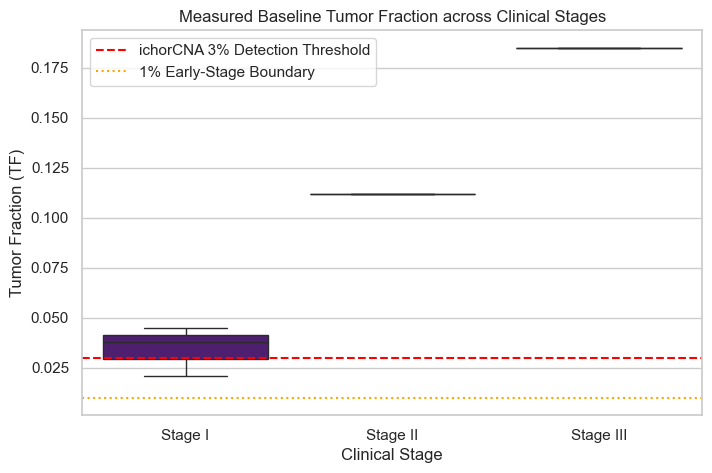

In [5]:
cancer_df = df[df["condition"] == "Cancer"].copy()

plt.figure(figsize=(8, 5))
sns.boxplot(data=cancer_df, x="stage", y="measured_tf", palette="magma")
plt.axhline(0.03, color="red", linestyle="--", label="ichorCNA 3% Detection Threshold")
plt.axhline(0.01, color="orange", linestyle=":", label="1% Early-Stage Boundary")
plt.title("Measured Baseline Tumor Fraction across Clinical Stages")
plt.ylabel("Tumor Fraction (TF)")
plt.xlabel("Clinical Stage")
plt.legend()
plt.show()

## 5. Pilot Cohort Selection for In Silico Titration
Identify balanced donor pairs (healthy plasma background + high-confidence cancer cases) for read mixing.

In [6]:
healthy_donors = df[df["condition"] == "Healthy"]
cancer_donors = df[df["condition"] == "Cancer"]

print(f"Available Healthy Control Donors: {len(healthy_donors)}")
print(f"Available Cancer Patient Donors: {len(cancer_donors)}")

# Target titration matrix preview
titration_targets = config["in_silico_dilution"]["fractions"]
print(f"Each cancer patient will be titrated at: {titration_targets}")

Available Healthy Control Donors: 3
Available Cancer Patient Donors: 5
Each cancer patient will be titrated at: [0.1, 0.05, 0.01, 0.001]
